### **Project work part 2 - IND320**
### Malk

##### **Imports and load data**

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import requests

import tomllib
import pandas as pd
from entsoe import EntsoePandasClient

import os
import sys
from pathlib import Path

from cassandra.cluster import Cluster
import pyspark
from pyspark.sql import SparkSession
from pyspark.sql.types import (
    StructType, StructField, StringType,
    IntegerType, TimestampType, DoubleType
)
from pymongo import MongoClient, UpdateOne



In [ ]:
#fetching the data

#Base address of the NVE Magasinstatistikk API
BASE_URL = "https://biapi.nve.no/magasinstatistikk"

def fetch_json(endpoint):
    """Call one API endpoint and return the parsed JSON."""
    response = requests.get(
        f"{BASE_URL}{endpoint}",
        headers={"Accept": "application/json"},
        timeout=60,
    )
    response.raise_for_status()
    return response.json()

df_file = pd.DataFrame(fetch_json("/api/Magasinstatistikk/HentOffentligData"))

##### **Describing the dataset and preprocessing**

In [3]:
#general information about the data
#size of the dataset
# the first 5 rows of the dataset
#information about the columns of the dataset

print(df_file.shape)
print(df_file.head())
print(df_file.info())

(14922, 11)
      dato_Id omrType  omrnr  iso_aar  iso_uke  fyllingsgrad  kapasitet_TWh  \
0  1995-09-03      EL      4     1995       35      0.944721      21.079208   
1  2020-11-15      EL      1     2020       46      0.974361       6.003264   
2  2011-08-28      EL      4     2011       34      0.786499      21.079208   
3  1998-07-05      EL      3     1998       27      0.793969       8.920932   
4  2011-03-27      EL      4     2011       12      0.300820      21.079208   

   fylling_TWh neste_Publiseringsdato  fyllingsgrad_forrige_uke  \
0    19.913979    0001-01-01T00:00:00                  0.936888   
1     5.849344    2020-11-25T13:00:00                  0.997406   
2    16.578772    0001-01-01T00:00:00                  0.787193   
3     7.082947    0001-01-01T00:00:00                  0.733812   
4     6.341054    0001-01-01T00:00:00                  0.311122   

   endring_fyllingsgrad  
0              0.007833  
1             -0.023046  
2             -0.000694  
3     

In [4]:
#describing the dataset in a more statistical sense 
#along with number of observations for each column
print(df_file.describe())
print(df_file.isna().sum())

              omrnr       iso_aar       iso_uke  fyllingsgrad  kapasitet_TWh  \
count  14922.000000  14922.000000  14922.000000  14922.000000   14922.000000   
mean       2.333333   2010.393245     26.443908      0.618948      29.145860   
std        1.490762      9.173142     15.011341      0.214686      22.739068   
min        0.000000   1995.000000      1.000000      0.051653       6.003264   
25%        1.000000   2002.000000     13.000000      0.456817      17.390587   
50%        2.000000   2010.000000     26.000000      0.648094      23.237715   
75%        3.000000   2018.000000     39.000000      0.801885      34.043590   
max        5.000000   2026.000000     53.000000      1.020072      87.437580   

        fylling_TWh  fyllingsgrad_forrige_uke  endring_fyllingsgrad  
count  14922.000000              14922.000000          14922.000000  
mean      18.142298                  0.618940              0.000008  
std       15.962981                  0.214672              0.031334  

The dataset looks complete in the sense of no missing values in any of the columns. Stay tuned to find out if this truly is the case. The first registration was made in 1996 (min-value for iso-aar) while the latest registration was made in 2026.

Some of the headers explain themselves, others are not that easy to interpret. 

In [5]:
df = df_file.copy() #renaming

#renaming the columns of the dataset
df = df.rename(columns={'dato_Id': 'Date', "omrType": "Area_type", "omrnr": "Area_number",
                        "iso_aar": "ISO_year","iso_uke": "ISO_week", 
                        "fyllingsgrad": "Filling_level", "kapasitet_TWh": "Capacity_TWh", 
                        "fylling_TWh": "Filling_TWh",
                        "neste_Publiseringsdato": "Next_publishdate",
                        "fyllingsgrad_forrige_uke": "Filling_level_prev_week", 
                        "endring_fyllingsgrad": "Change_filling_level"})

#sorting the dataframe by date so the datapoints become sequential
df = df.sort_values("Date") 

In [6]:
#checking if the changes worked
df.head()

,Date,Area_type,Area_number,ISO_year,ISO_week,Filling_level,Capacity_TWh,Filling_TWh,Next_publishdate,Filling_level_prev_week,Change_filling_level
3014,1995-01-08,EL,4,1995,1,0.558864,21.079208,11.780413,0001-01-01T00:00:00,0.801348,-0.242484
3111,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
4579,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349
7282,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,0001-01-01T00:00:00,0.777604,-0.146657
7882,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869


We see that "Next_publishdate" for some measurements are 0001-01-01T00:00:00, which doesnt give any intiuitive sense, but it could be that before that date, the system wasnt digitalised. This date is then the minimum date. 

We can observe that the column "Date" is in the format off YYYY-MM-DD, but the type is an object, and the same is for "Next_Publishdate". 

In [7]:
# converting the date columns to datetime format
for col in ["Date", "Next_publishdate"]:
    df[col] = pd.to_datetime(df[col], format="ISO8601", errors="coerce")

print(df[["Date", "Next_publishdate"]].dtypes)

Date                datetime64[us]
Next_publishdate    datetime64[us]
dtype: object


In [8]:
#checking if the changes were made
df.head()

,Date,Area_type,Area_number,ISO_year,ISO_week,Filling_level,Capacity_TWh,Filling_TWh,Next_publishdate,Filling_level_prev_week,Change_filling_level
3014,1995-01-08,EL,4,1995,1,0.558864,21.079208,11.780413,1-01-01,0.801348,-0.242484
3111,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,1-01-01,0.614288,0.002160
4579,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,1-01-01,0.596027,0.006349
7282,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,1-01-01,0.777604,-0.146657
7882,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,1-01-01,0.583705,0.033869


NaT = Not a Time. Happens when there are missing dates within a dataframe. 0001-01-01T00:00:00 is not a date and the value therefore becomes NaT. So even though isna().sum() gave us that there is no missing values, by actually inspecting the dataset we see that there is indeed missing values. 

##### **Plotting each column**

In [9]:
print(df["Area_type"].unique()) #checking unique values in the Area_type column
print(df.groupby("Area_type")["Area_number"].unique())

<ArrowStringArray>
['EL', 'NO', 'VASS']
Length: 3, dtype: str
Area_type
EL      [4, 5, 3, 2, 1]
NO                  [0]
VASS          [3, 2, 1]
Name: Area_number, dtype: object


This columns seems to hold information about how the data is categorized in areas, wether it is
- NO: The whole country of Norway
- EL: one of the five electricity price areas
    - EL1
    - EL2
    - EL3
    - EL4
    - EL5
- VASS: river basin area (Vassdragsområde)
    - VASS1
    - VASS2
    - VASS3

Text(0.5, 1.0, 'Observations by Area')

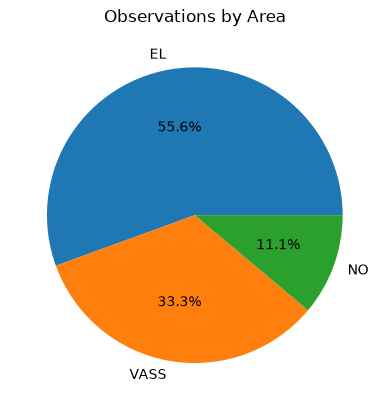

In [10]:
# how many observations are made for each area type
df["Area_type"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Observations by Area")

Text(0.5, 1.0, 'Observations for each area number within the area type')

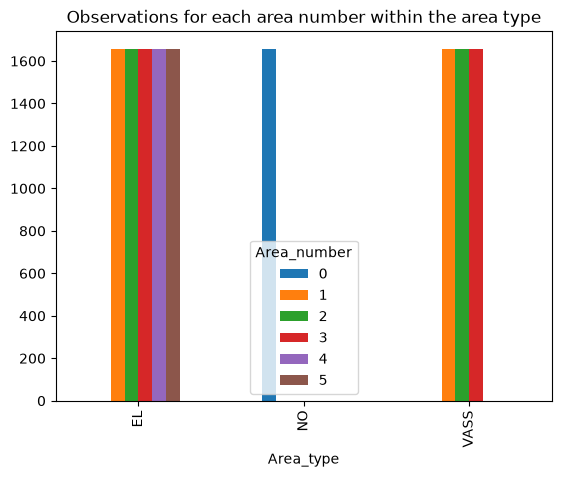

In [11]:
#different area numbers for each area type
df.groupby(["Area_type", "Area_number"]).size().unstack(fill_value=0).plot(kind="bar")
plt.title("Observations for each area number within the area type")

NO has no area number as it covers the whole country, so the default area number is zero. However, each area number is represented in the same amount, this can also seen in the pie chart.

Text(0.5, 1.0, 'Observations by ISO year')

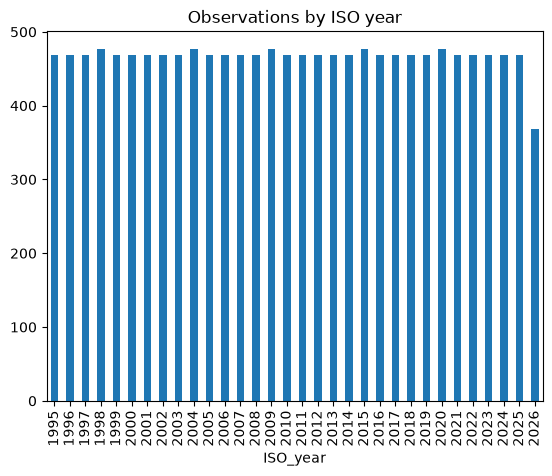

In [12]:
#how many observations there are for each ISO year
#ISO years are essentially observations throughout the years, grouped by year
df["ISO_year"].value_counts().sort_index().plot(kind="bar")
plt.title("Observations by ISO year")

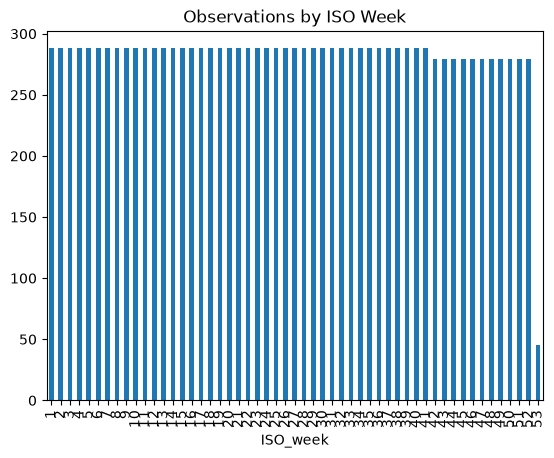

In [13]:
#how many observations there are for each ISO week
#ISO weeks are essentially obervations throughout the years, grouped by week number
df["ISO_week"].value_counts().sort_index().plot(kind="bar")
plt.title("Observations by ISO Week")
plt.show()

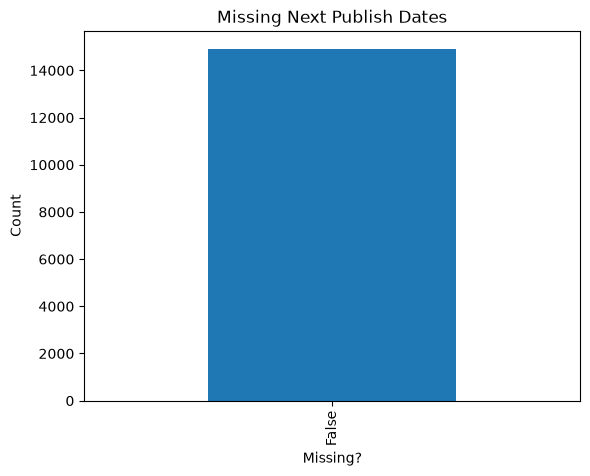

In [14]:
#how many of the Next_publishdate is NaT
df["Next_publishdate"].isna().value_counts().plot(kind="bar")
plt.title("Missing Next Publish Dates")
plt.xlabel("Missing?")
plt.ylabel("Count")
plt.show()

Even though we showed above that there was no missing values, looking further into the data, we now see that the missing values were replaced by a default date, and then when we transfomed the column to have a proper date-format, the missing values became marked as NaT. 



It doesn't make sense to plot the Date-column by itself, so in stead i will group the measurements by month, and then look at when the measurements are taken throughout the seasons of the year. 

Text(0, 0.5, 'Number of Measurements')

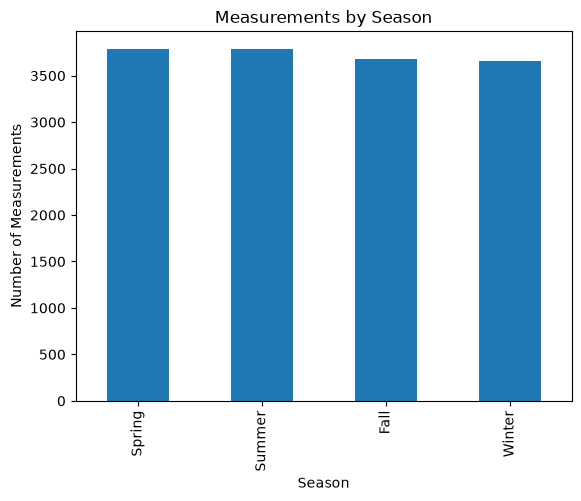

In [15]:
#count the number of measurement for each month of the year
#then assign the months an index from 1-12
monthly_measurements = df["Date"].dt.month.value_counts().sort_index()

#assign the indexed months to their respective season
#sum all the observations for each month within the season
spring_months = monthly_measurements[[3, 4, 5]].sum()
summer_months = monthly_measurements[[6, 7, 8]].sum()
fall_months = monthly_measurements[[9, 10, 11]].sum()
winter_months = monthly_measurements[[12, 1, 2]].sum()

#create a pandas series where each season get its corresponding
#number of measurements
seasonal_measurements =  pd.Series(
    [spring_months, summer_months, fall_months, winter_months],
    index=["Spring", "Summer", "Fall", "Winter"]
)

seasonal_measurements.plot(kind="bar")

plt.title("Measurements by Season")
plt.xlabel("Season")
plt.ylabel("Number of Measurements")

Judging by this, it looks like there are fewer measurements during the colder months in contrary to the summer and spring months. However, the difference doesnt seem signficant. 

Text(0.5, 0, 'Filling Level')

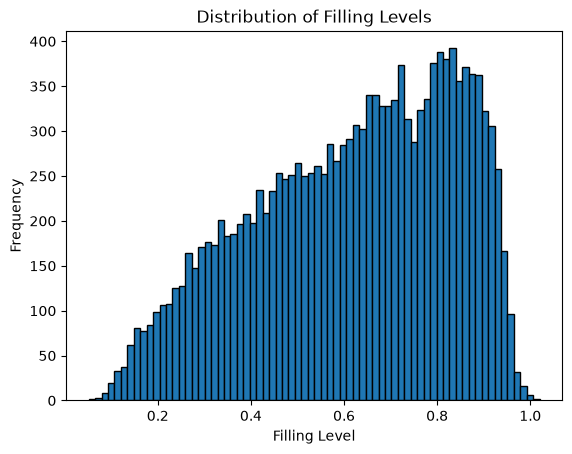

In [16]:
df["Filling_level"].plot(kind="hist", bins=70, edgecolor="black") #tried different bin sizes, 70 seems good
plt.title("Distribution of Filling Levels")
plt.xlabel("Filling Level")


The distribution of the filling level is slightly left-skewed. This means that most reservoirs have relatively high filling levels, but there are some observations with unusually low filling levels. 

Text(0.5, 0, 'Capacity (TWh)')

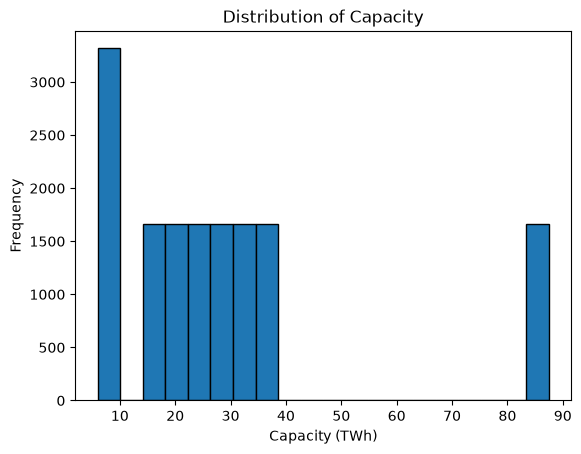

In [17]:
df["Capacity_TWh"].plot(kind="hist", bins=20, edgecolor="black")

plt.title("Distribution of Capacity")
plt.xlabel("Capacity (TWh)")

The distribution of capacity shows that most observations have a capacity of around 10 TWh. The remaining observations are mainly distributed between 15 and 40 TWh, with a few observations having a capacity of approximately 85 TWh.

Text(0.5, 0, 'Filling (TWh)')

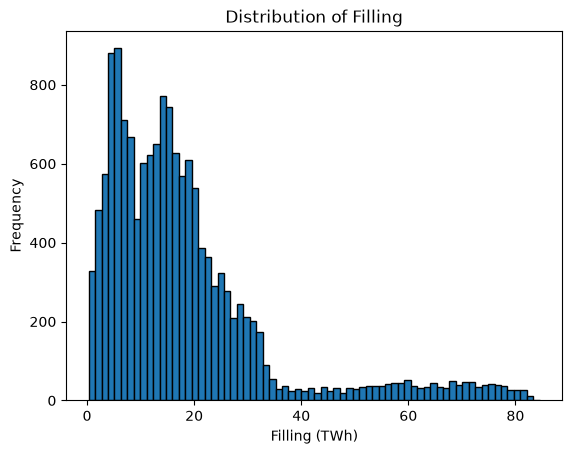

In [18]:
df["Filling_TWh"].plot(kind="hist", bins=70, edgecolor="black")

plt.title("Distribution of Filling")
plt.xlabel("Filling (TWh)")

The distribution of Filling TWh is right-skewed. This means that most observations are concentrated at lower values, while a smaller number of observations have higher values, creating a longer tail toward the right.


Text(0.5, 0, 'Filling level (precentage)')

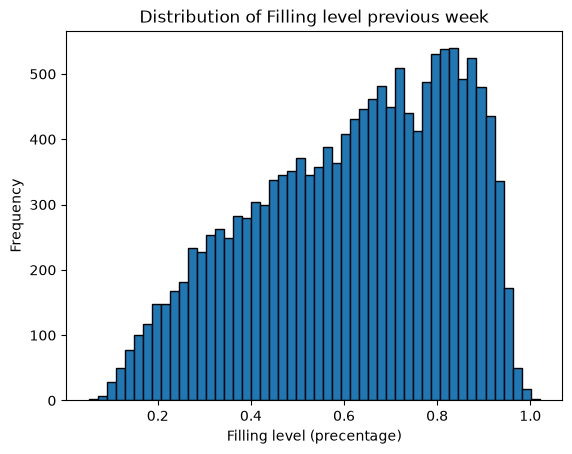

In [19]:
df["Filling_level_prev_week"].plot(kind="hist", bins=50, edgecolor="black")

plt.title("Distribution of Filling level previous week")
plt.xlabel("Filling level (precentage)")

The distributiomn of the filling level for the previous week is slightly left-skewed. Most observations are concentrated toward the higher filling levels, while the observations gradually decrease toward the lower values. However, the skewness is not very pronounced.

Text(0.5, 0, 'Change in filling level (precentage)')

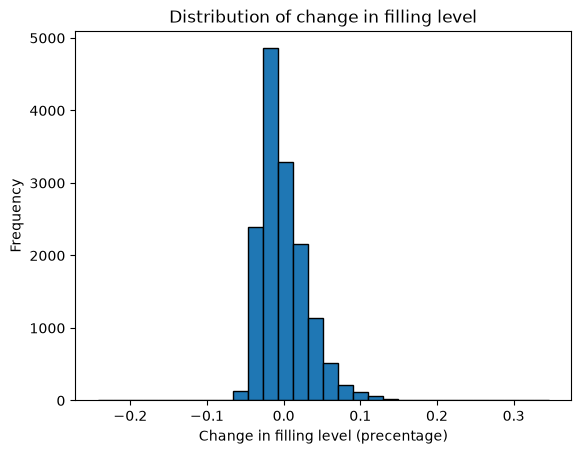

In [20]:
df["Change_filling_level"].plot(kind="hist", bins=30, edgecolor="black")

plt.title("Distribution of change in filling level")
plt.xlabel("Change in filling level (precentage)")

In [21]:
# counting the number of observations for the change in filling level
below_zero = (df["Change_filling_level"] < 0).sum() #the change is negative = less filling than last measured
above_zero = (df["Change_filling_level"] > 0).sum() #the change is positive = more filling than last measured
at_zero = (df["Change_filling_level"] == 0).sum() #the change is zero = no change from last time

print("Below 0:", below_zero)
print("Above 0:", above_zero)
print("Exactly 0:", at_zero)

Below 0: 8708
Above 0: 6214
Exactly 0: 0


Then we have the distribution of the change in filling level. Most observations are below zero, meaning on the left side, giving a distribution with a tail on right-side, making it right-skewed. 

##### **Plotting columns against each other**

Plotting the measurements over time, where the datapoints are grouped by area_type and then looking at area_number for each area_type.

In [22]:
el_area = df[df["Area_type"] == "EL"].copy() #filtering the dataframe to only include rows where Area_type is "EL"
no_area = df[df["Area_type"] == "NO"].copy() #filtering the dataframe to only include rows where Area_type is "NO"
vass_area = df[df["Area_type"] == "VASS"].copy() #filtering the dataframe to only include rows where Area_type is "VASS"

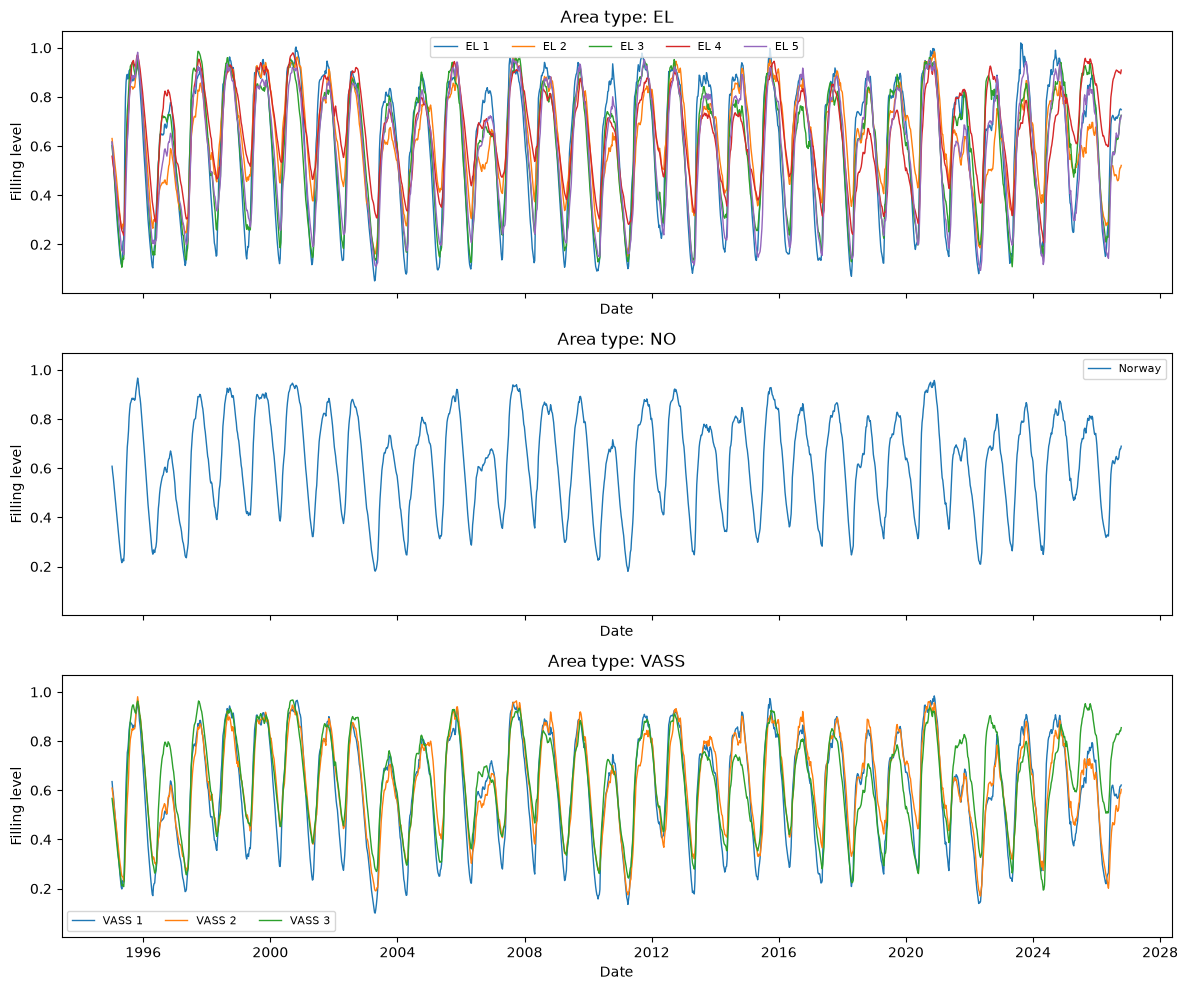

In [23]:
#create 3 plots, one for each Area_type
#the plots are stacked vertically (3 rows, 1 column)
fig, axes = plt.subplots(3, 1, figsize=(12, 10),
    sharex=True, #use the same Date axis for all plots
    sharey=True #use the same Filling level scale for all plots
)

#loop through each Area_type and its corresponding plot
for ax, area_type in zip(axes, df["Area_type"].unique()):

    #select only observations belonging to the current Area_type
    #and sort them chronologically by Date
    subset = df[df["Area_type"] == area_type].sort_values("Date")

    #group the data by Area_number
    for number, area in subset.groupby("Area_number"):
        #create a label for the legend
        #if the area type is NO, call it "Norway"
        #else use the Area_type and Area_number
        label = "Norway" if area_type == "NO" else f"{area_type} {number}"

        #plot the Filling_level over Date for the current area
        ax.plot(
            area["Date"],
            area["Filling_level"],
            label=label,
            linewidth=1
        )

    #Adding a title showing which Area_type is being displayed
    ax.set_title(f"Area type: {area_type}")
    ax.set_ylabel("Filling level")
    ax.set_xlabel("Date")
    #legend showing which line belongs to which area
    ax.legend(ncol=5, fontsize=8)

plt.tight_layout()
plt.show()

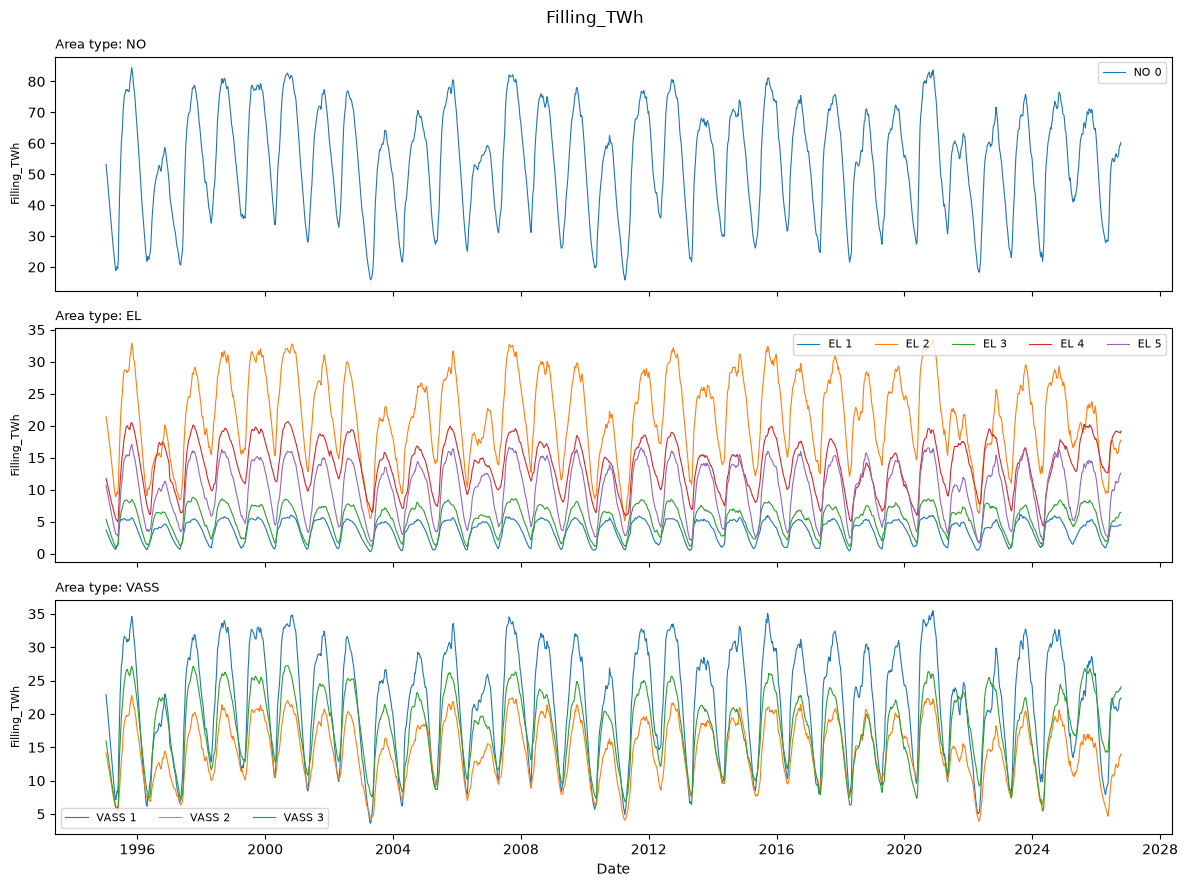

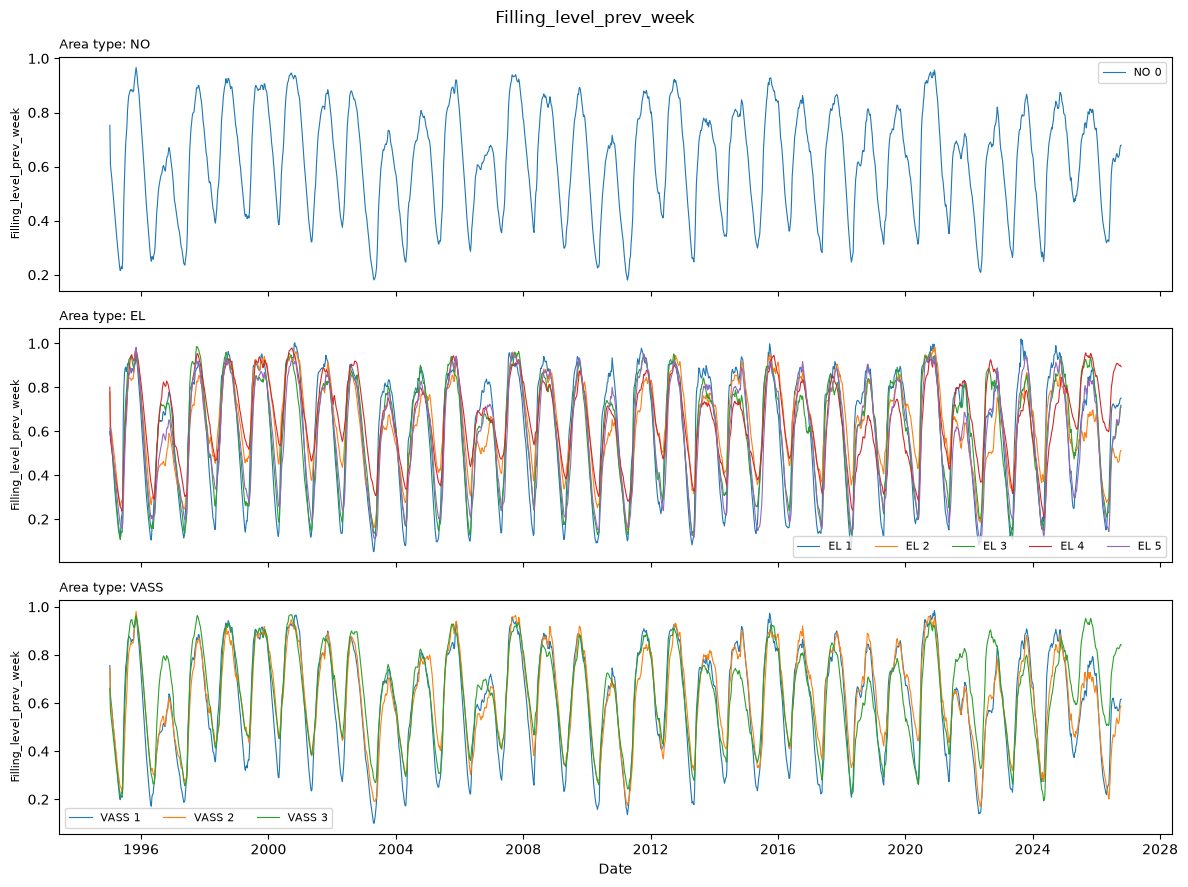

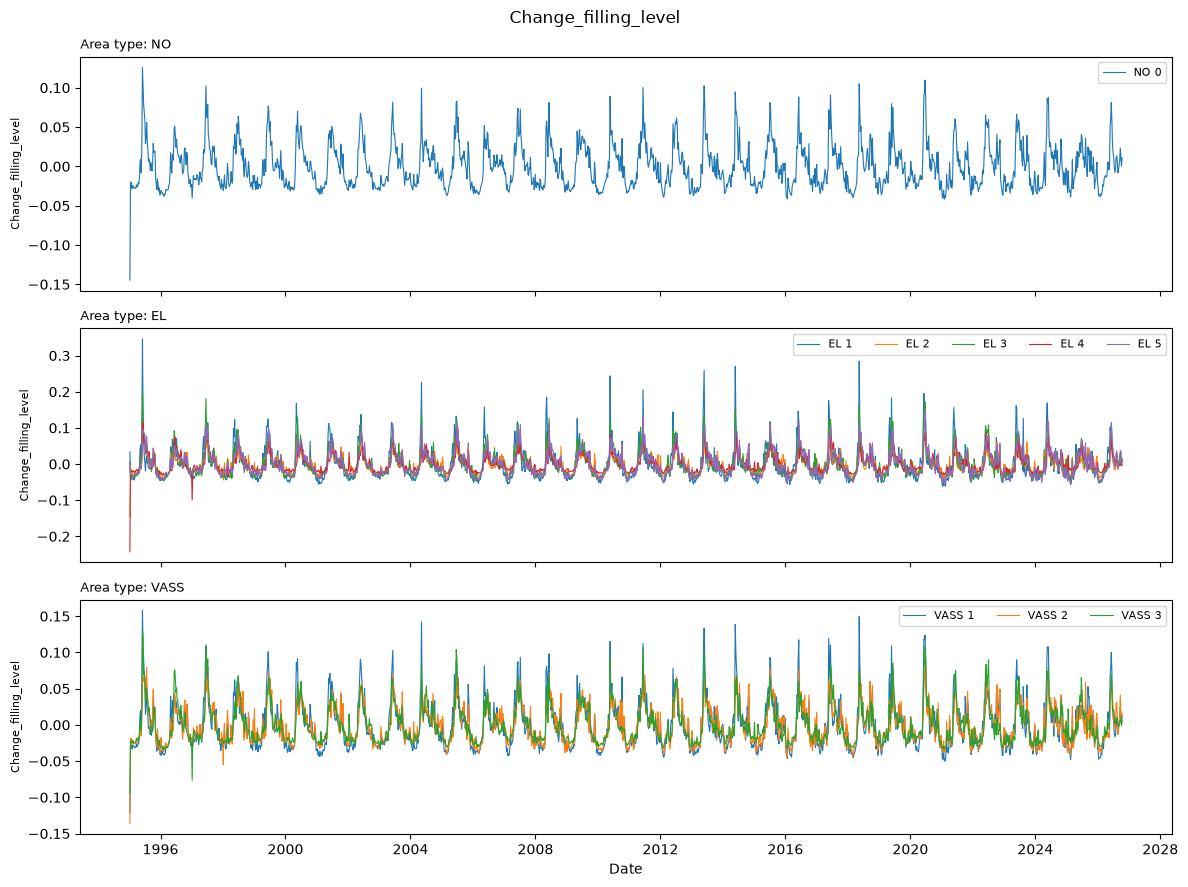

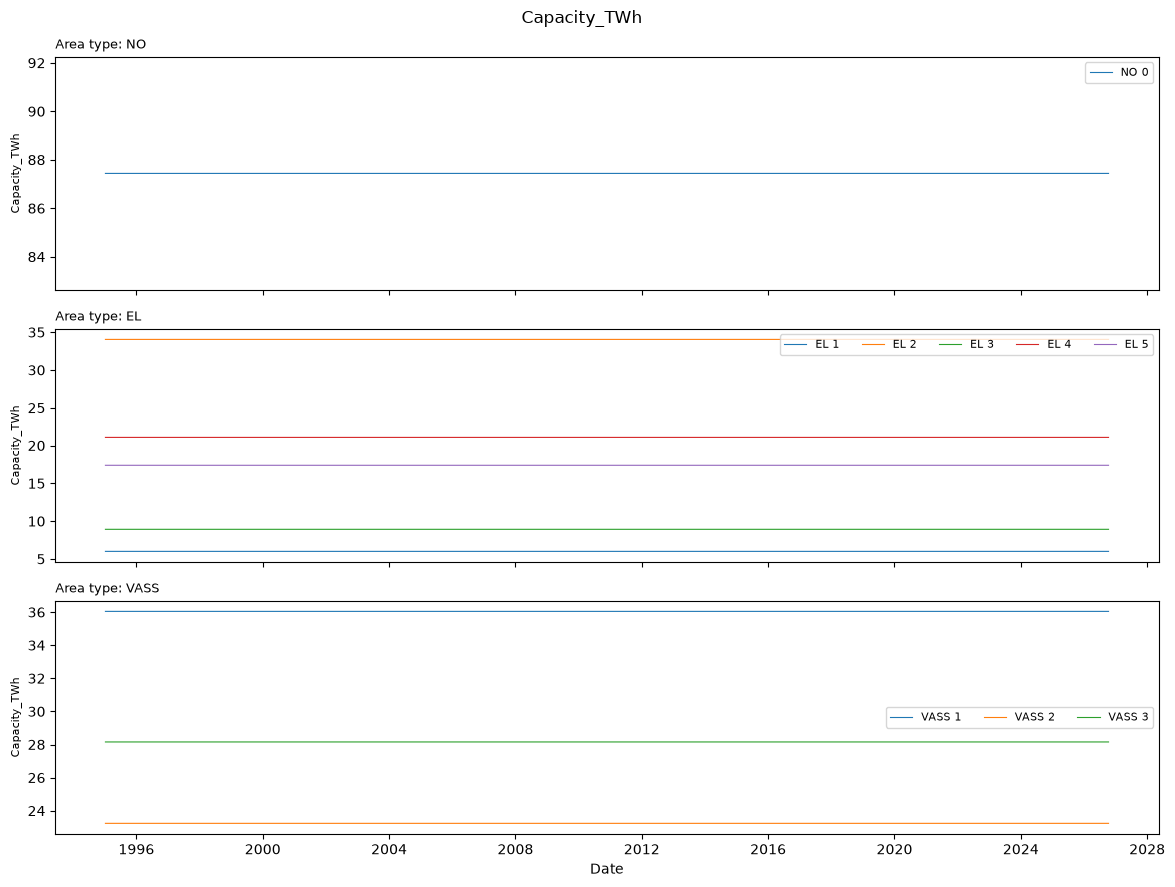

In [24]:
#Lisy of measurement columns that we want to plot
measure_cols = ["Filling_TWh", "Filling_level_prev_week", "Change_filling_level", "Capacity_TWh"]

#Looping through the columns
#for each measure, a figure is created
for col in measure_cols:
    #3 subplots are created for each area type
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

    #loop through the area tyoes and their df
    for ax, area_df, area_type in zip(axes, [no_area, el_area, vass_area], ["NO", "EL", "VASS"]):
        #sirting the data by date and then group by Are_number
        for number, g in area_df.sort_values("Date").groupby("Area_number"):
            #plot the selected measurement over time
            #each area number gets its line
            ax.plot(g["Date"], g[col], label=f"{area_type} {number}", linewidth=0.8)

        #which Area_type is being shown
        ax.set_title(f"Area type: {area_type}", loc="left", fontsize=9)
        ax.set_ylabel(col, fontsize=8)
        ax.legend(ncol=5, fontsize=8)

    axes[-1].set_xlabel("Date") #naming the bottom x-axis
    #naming the figure the selected measurement
    fig.suptitle(col)
    plt.tight_layout()
    plt.show()

* Filling (TWh) against date:
  The different colors represent the different area numbers within each area type. VASS-1, EL-2 and NO appear to follow similar trends over time, although they are on different scales. This suggests that the filling levels in these areas tend to increase and decrease in similar periods.

* Filling level in the previous week against date:
  Here, EL-5, VASS-2 and NO appear to follow similar trends over time. The filling level in the previous week also shows relatively consistent patterns between the different areas.

* Change in filling level against date:
  The changes in filling level appear to be relatively small throughout the observed period. There are some larger peaks, particularly around 1996. These peaks could indicate periods with larger changes in reservoir filling levels.

* Capacity (TWh) against date:
  The capacity appears to remain constant for the different area types and area numbers throughout the observed period. This is expected because the capacity represents the maximum storage capacity of the reservoirs rather than the amount of water currently stored. The graphs also show that the same area-number series are present throughout the period.


##### Plotting all the columns for one area_type

Only plotting all the columns for Area_type="NO" so it doesnt look as chaotic. 

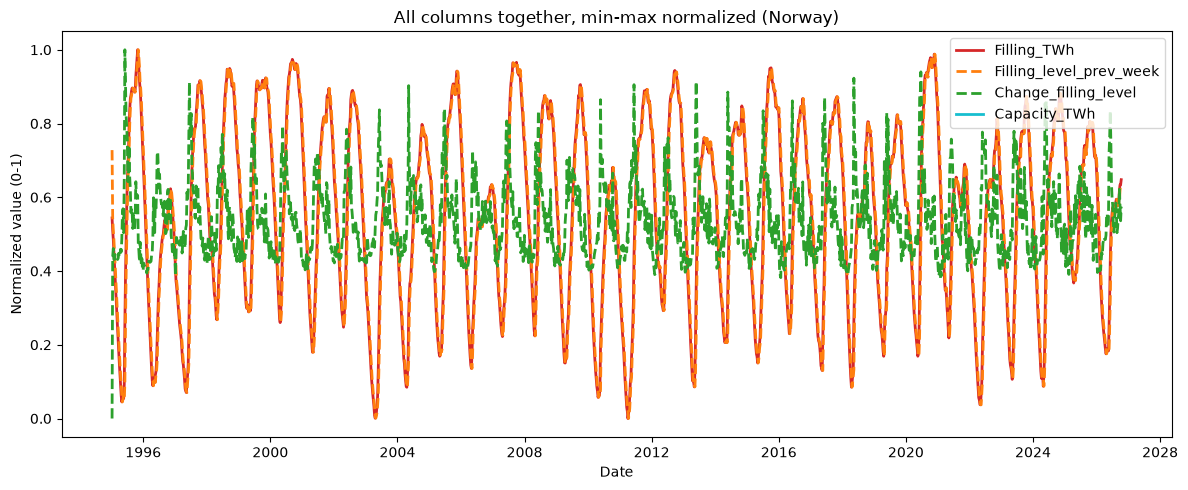

In [25]:
#normalizes all the measurement column to a scale from 0-1
#Makes the columns comparable since they have different scales. 
norm = (no_area[measure_cols ] - no_area[measure_cols ].min()) / (no_area[measure_cols ].max() - no_area[measure_cols].min())

#different line styles to easier differentiate the lines
styles = ["-", "--", "--", "-"]
#different colors for the lines
colors = ["tab:red", "tab:orange", "tab:green", "tab:cyan"]

fig, ax = plt.subplots(figsize=(12, 5))

#looping through each measurement column, linestyle and color
for col, style, color in zip(measure_cols, styles, colors):
    #Plotting the normaøozed measurements over time
    ax.plot(no_area["Date"], norm[col], label=col, linewidth=2.0,
            linestyle=style, color=color)

ax.set_xlabel("Date")
ax.set_ylabel("Normalized value (0-1)")
ax.set_title("All columns together, min-max normalized (Norway)")
ax.legend()
plt.tight_layout()
plt.show()

In [26]:
#calculate the correlation between the normalized measurements
correlations = norm.corr()

print(correlations)

                         Filling_TWh  Filling_level_prev_week  \
Filling_TWh                 1.000000                 0.990002   
Filling_level_prev_week     0.990002                 1.000000   
Change_filling_level        0.070054                -0.071353   
Capacity_TWh                     NaN                      NaN   

                         Change_filling_level  Capacity_TWh  
Filling_TWh                          0.070054           NaN  
Filling_level_prev_week             -0.071353           NaN  
Change_filling_level                 1.000000           NaN  
Capacity_TWh                              NaN           NaN  


In [47]:
#describing the Capacity column for area type NO
#since we get NaN-values
print(no_area["Capacity_TWh"].describe())

count    1.658000e+03
mean     8.743758e+01
std      1.421514e-14
min      8.743758e+01
25%      8.743758e+01
50%      8.743758e+01
75%      8.743758e+01
max      8.743758e+01
Name: Capacity_TWh, dtype: float64


The normalized measurements show that Filling TWh and Filling level in the previous week follow very similar patterns over time. This is also supported by their very high correlation of 0.990. Change in filling level behaves differently and has very little relationship with the other two variables.

Capacity TWh is not visible in the normalized plot because its value is constant in the data for the area we examined. Since the capacity does not change, it cannot be normalized in the same way as the other variables. Therefore, we cannot use this plot to compare the development of capacity with the other measurements.

Overall, the results show that Filling TWh and Filling level in the previous week change in a very similar way, while Change in filling level follows a different pattern.




## **Entsoe data**

In [ ]:
# Reading the entose token
with open("../.streamlit/secrets.toml", "rb") as f:
    token = tomllib.load(f)["entsoe"]["token"]

client = EntsoePandasClient(api_key=token)

# Download the last two years till today
end = pd.Timestamp.today(tz="Europe/Oslo").normalize()
start = end - pd.DateOffset(years=2)

# Norwegian price areas and their neighbouring areas.
connections = [
    ("NO_1", "SE_3"),
    ("NO_2", "DK_1"),
    ("NO_2", "NL"),
    ("NO_2", "DE_LU"),
    ("NO_2", "GB"),
    ("NO_3", "SE_2"),
    ("NO_4", "SE_1"),
    ("NO_4", "SE_2"),
    ("NO_4", "FI"),
]

frames = []
failed_requests = []

for a, b in connections:
    # Query each connection in both directions.
    # Checking for-loops are running
    print("hei1")
    for src, dst in [(a, b), (b, a)]:
        # Checking for-loops are running
        print("hallo")
        try:
            flow = client.query_crossborder_flows(
                src, dst, start=start, end=end
            )

            if flow.empty:
                raise ValueError("The API returned no observations.")

            frames.append(pd.DataFrame({
                # Store timestamps consistently in UTC.
                "Time": flow.index.tz_convert("UTC"),
                "Connection": f"{a}-{b}",
                "From": src,
                "To": dst,
                "Direction": (
                    "out of Norway"
                    if src.startswith("NO_")
                    else "into Norway"
                ),
                "Flow_MW": flow.values,
            }))

        except Exception as e:
            # Record failures so incomplete downloads are clearly identified.
            failed_requests.append((src, dst, type(e).__name__))
            print(f"Failed {src} -> {dst}: {type(e).__name__}")


# Combine and sort the downloaded data.
flows = pd.concat(frames, ignore_index=True)
flows = flows.sort_values(
    ["Connection", "Direction", "Time"]
).reset_index(drop=True)

hei1
hallo
hallo
hei1
hallo
hallo
hei1
hallo
hallo
hei1
hallo
hallo
hei1
hallo
hallo
hei1
hallo
hallo
hei1
hallo
hallo
hei1
hallo
hallo
hei1
hallo
hallo
Shape: (1038036, 6)
Connection  Direction    
NO_1-SE_3   into Norway      45234
            out of Norway    45234
NO_2-DE_LU  into Norway      70080
            out of Norway    70080
NO_2-DK_1   into Norway      57762
            out of Norway    57762
NO_2-GB     into Norway      70080
            out of Norway    70080
NO_2-NL     into Norway      70080
            out of Norway    70080
NO_3-SE_2   into Norway      45234
            out of Norway    45234
NO_4-FI     into Norway      70080
            out of Norway    70080
NO_4-SE_1   into Norway      45234
            out of Norway    45234
NO_4-SE_2   into Norway      45234
            out of Norway    45234
dtype: int64
UTC timestamps: 2024-10-18 22:00:00+00:00 to 2026-10-18 21:45:00+00:00


In [ ]:
#Save downloaded data so we dont have to rerun the above cell
#flows.to_csv("entsoe_flows.csv", index=False)

In [66]:
#reading the saved file of entsoe data
flows = pd.read_csv("entsoe_flows.csv")
flows["Time"] = pd.to_datetime(flows["Time"], utc=True)

Cassandra and pyspark connection

In [67]:
# Where java is
java_home = Path(r"C:\Program Files\Microsoft\jdk-17.0.20.101-hotspot")

if not (java_home / "bin" / "java.exe").is_file():
    raise FileNotFoundError(f"Java installation not found: {java_home}")


#Tell pyspark where java is
os.environ["JAVA_HOME"] = str(java_home)

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

os.environ["HADOOP_HOME"] = r"C:\winutils-temp\hadoop-3.3.1"

In [68]:
# Connect to local Cassandra in docker
cluster = Cluster(["localhost"], port=9042)
session = cluster.connect()

# Create the project keyspace
#Simplestrategy with rep_fac=1 keeps one copy of each row
session.execute("""
    CREATE KEYSPACE IF NOT EXISTS ind320
    WITH replication = {
        'class': 'SimpleStrategy',     
        'replication_factor': 1
    }
""")

# table for cross-border flow observations
# one row per connection, direction and timestamp
session.execute("""
    CREATE TABLE IF NOT EXISTS ind320.crossborder_flows (
        connection text,
        direction text,
        year int,
        time timestamp,
        from_area text,
        to_area text,
        flow_mw double,
        PRIMARY KEY ((connection, direction, year), time)
    )
""")

# Checking that it worked
print("Project keyspace and table are ready.")
#close the connection since we are done since we are done with this session
cluster.shutdown()

Project keyspace and table are ready.


In [69]:
spark = (
    SparkSession.builder
    .appName("IND320_Part2")
    .master("local[2]")
    #download the spark-cassandra connector
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    #where spark finds cassandra
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    .config("spark.sql.session.timeZone", "UTC") #sets sparks timezoen to UTC
    .getOrCreate()
)

ConnectionRefusedError: [WinError 10061] Kan ikke koble til fordi målmaskinen avslo tilkobling

Reading data through Spark

In [ ]:
#timestamps in UTC 
# use Norwegian calendar years for partitioning
prepared = flows.copy()
prepared["Time"] = pd.to_datetime(prepared["Time"], utc=True)
prepared["Year"] = prepared["Time"].dt.tz_convert("Europe/Oslo").dt.year

#defining explicitly teh spark schema
schema = StructType([
    StructField("connection", StringType(), False),
    StructField("direction", StringType(), False),
    StructField("year", IntegerType(), False),
    StructField("time", TimestampType(), False),
    StructField("from_area", StringType(), False),
    StructField("to_area", StringType(), False),
    StructField("flow_mw", DoubleType(), True),
])

# what datetype the rows shouuld be
rows = [(
        str(connection),
        str(direction),
        int(year),
        time.to_pydatetime(),
        str(from_area),
        str(to_area),
        None if pd.isna(power) else float(power),) #NaN becomes None, else a float
    #iterate row by row    
    for connection, direction, year, time, from_area, to_area, power 
    in prepared[
        ["Connection", "Direction", "Year", "Time", "From", "To", "Flow_MW"]
    ].itertuples(index=False, name=None)
]

spark.conf.set("spark.sql.session.timeZone", "UTC") #Spark interpret timestamps as UTC
spark_flows = spark.createDataFrame(rows, schema=schema) # Build the soark dataframe

#Append performs upserts using the primary key
#Rerunning doesnt duplicate records with the same key
(
    spark_flows.write
    .format("org.apache.spark.sql.cassandra")
    .options(keyspace="ind320", table="crossborder_flows")
    .mode("append")
    .save()
)

In [ ]:
#read the stored entsoe data from Cassandra using Spark
stored_flows = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(keyspace="ind320", table="crossborder_flows")
    .load()
)

#selecting the relevant columns
selected_flows = stored_flows.select(
    "time",
    "connection",
    "direction",
    "flow_mw"
)

#checking how many observations exist for each connection and direction
selected_flows.groupBy(
    "connection", "direction"
).count().orderBy("connection", "direction").show(30, truncate=False) #up to 30 rows, without truncating long strings

+----------+-------------+-----+
|connection|direction    |count|
+----------+-------------+-----+
|NO_1-SE_3 |into Norway  |45234|
|NO_1-SE_3 |out of Norway|45234|
|NO_2-DE_LU|into Norway  |70080|
|NO_2-DE_LU|out of Norway|70080|
|NO_2-DK_1 |into Norway  |57762|
|NO_2-DK_1 |out of Norway|57762|
|NO_2-GB   |into Norway  |70080|
|NO_2-GB   |out of Norway|70080|
|NO_2-NL   |into Norway  |70080|
|NO_2-NL   |out of Norway|70080|
|NO_3-SE_2 |into Norway  |45234|
|NO_3-SE_2 |out of Norway|45234|
|NO_4-FI   |into Norway  |70080|
|NO_4-FI   |out of Norway|70080|
|NO_4-SE_1 |into Norway  |45234|
|NO_4-SE_1 |out of Norway|45234|
|NO_4-SE_2 |into Norway  |45234|
|NO_4-SE_2 |out of Norway|45234|
+----------+-------------+-----+



We see that the same amount exported to an area is same amount imported from an area. 

In [ ]:
plot_data = selected_flows.toPandas() #spart datafram to pandas dataframe

# Convert UTC timestamps to Norwegian local time for year/month selection.
plot_data["time"] = (
    pd.to_datetime(plot_data["time"], utc=True)
    .dt.tz_convert("Europe/Oslo")
)

#sort by connection, direction then time
#replacing old indexing
plot_data = plot_data.sort_values(
    ["connection", "direction", "time"]
).reset_index(drop=True)

#looking at first five rows
plot_data.head()

,time,connection,direction,flow_mw
0,2024-10-19 00:00:00+02:00,NO_1-SE_3,into Norway,938.1250
1,2024-10-19 01:00:00+02:00,NO_1-SE_3,into Norway,760.9550
2,2024-10-19 02:00:00+02:00,NO_1-SE_3,into Norway,723.5400
3,2024-10-19 03:00:00+02:00,NO_1-SE_3,into Norway,742.2175
4,2024-10-19 04:00:00+02:00,NO_1-SE_3,into Norway,711.7750


Rows excluded because of missing values or unusual gaps: 2
Estimated energy (MWh):
direction
into Norway      6.138456e+06
out of Norway    1.623833e+06
Name: energy_mwh, dtype: float64


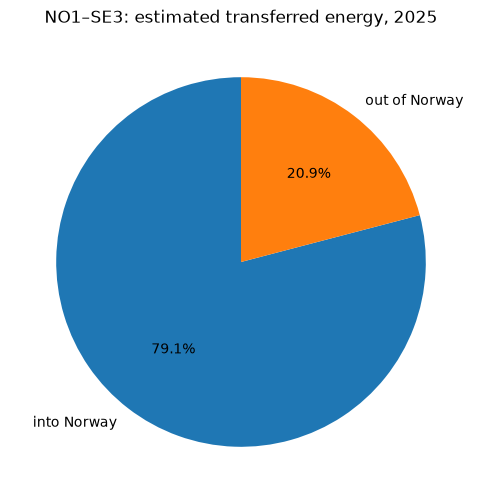

In [72]:
#selecting the Norway–Sweden connection
#area 1 for norway and 3 for Sweden
data = plot_data[
    plot_data["connection"] == "NO_1-SE_3"
].copy()

#one row per direction per timepoint
keys = ["direction", "time"]
# removing duplicates
data = data.drop_duplicates(keys).sort_values(keys)

#estimate each interval from the next timestamp in the same direction
next_time = data.groupby("direction")["time"].shift(-1)
#the interval length in hours
data["hours"] = (next_time - data["time"]).dt.total_seconds() / 3600

#only keeping 2025 data
data = data[data["time"].dt.year == 2025].copy()

#looking at 15-minutes and 1-hour intervals and must have a flow-value
valid = data["hours"].isin([0.25, 1.0]) & data["flow_mw"].notna()
#printing out the rows not fulfilling above req.
print("Rows excluded because of missing values or unusual gaps:", (~valid).sum())
#dropping the rows
data = data[valid].copy()

#converting power to energy
#then total imports and exports
#energy = power * time
data["energy_mwh"] = data["flow_mw"] * data["hours"]
#total energy per direction
annual = data.groupby("direction")["energy_mwh"].sum()

print("Estimated energy (MWh):")
print(annual)

#plot of the direction shares for NO1-SE3
annual.plot.pie(autopct="%1.1f%%", startangle=90, figsize=(6, 6))
plt.title("NO1–SE3: estimated transferred energy, 2025")
plt.show()

Most energy to Norway area 1, is imported from Sweden area 3 with almost 80% energy. 

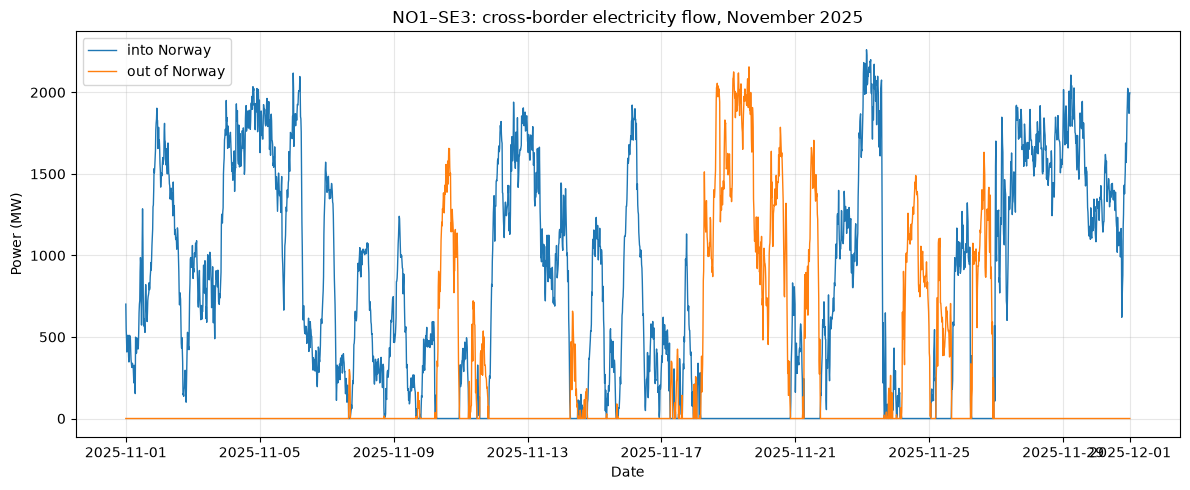

In [ ]:
#select january for the NO1-SE3 connection
november = plot_data[
    (plot_data["connection"] == "NO_1-SE_3") &
    (plot_data["time"].dt.year == 2025) &
    (plot_data["time"].dt.month == 11)
].copy()

#only looking at unique rows and dropping duplicates
november = november.drop_duplicates(
    ["time", "direction", "flow_mw"]
).sort_values("time")

fig, ax = plt.subplots(figsize=(12, 5))

#plotting the data by import/export
for direction, group in november.groupby("direction"):
    ax.plot(
        group["time"],
        group["flow_mw"],
        label=direction,
        linewidth=1,
    )

ax.set_title("NO1–SE3: cross-border electricity flow, November 2025")
ax.set_xlabel("Date")
ax.set_ylabel("Power (MW)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Spark into Mongodb

In [ ]:
#opening the secrets file
with open("../.streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)

#connecting using uri
mongo_client = MongoClient(
    secrets["mongo"]["uri"],
    tz_aware=True, # For timestamps 
)

#checking it connected
mongo_client.admin.command("ping")
print("Connected to MongoDB!")

#choosing the project database and collection
collection = mongo_client["ind320"]["crossborder_flows"]

Connected to MongoDB!


In [65]:
#use all data extracted from Cassandra through Spark
mongo_data = plot_data[
    ["time", "connection", "direction", "flow_mw"]
].copy()

#interate in bactches of 1000 rows
for start in range(0, len(mongo_data), 1000):
    batch = mongo_data.iloc[start:start + 1000]
    operations = []
    #iterating through each bath
    for row in batch.itertuples(index=False):
        #building the mongo document
        record = {
            "time": row.time.to_pydatetime(),  #need it in python format
            "connection": row.connection,
            "direction": row.direction,
            "flow_mw": None if pd.isna(row.flow_mw) else float(row.flow_mw), #NaN becomes None or float
        }

        key = {column: record[column] for column in keys} #our keys

        #upsert updates if the key exists
        #or else inserts it
        operations.append(
            UpdateOne(key, {"$set": record}, upsert=True)
        )

    #sending batch as one bulk write
    collection.bulk_write(operations, ordered=False)

    #To see progress
    print(
        f"Processed {min(start + 1000, len(mongo_data)):,} "
        f"of {len(mongo_data):,} rows",
        flush=True,
    )

print(f"Upload finished: {len(mongo_data):,} records processed.")

Processed 1,000 of 1,038,036 rows
Processed 2,000 of 1,038,036 rows
Processed 3,000 of 1,038,036 rows
Processed 4,000 of 1,038,036 rows
Processed 5,000 of 1,038,036 rows
Processed 6,000 of 1,038,036 rows
Processed 7,000 of 1,038,036 rows
Processed 8,000 of 1,038,036 rows
Processed 9,000 of 1,038,036 rows
Processed 10,000 of 1,038,036 rows
Processed 11,000 of 1,038,036 rows
Processed 12,000 of 1,038,036 rows
Processed 13,000 of 1,038,036 rows
Processed 14,000 of 1,038,036 rows
Processed 15,000 of 1,038,036 rows
Processed 16,000 of 1,038,036 rows
Processed 17,000 of 1,038,036 rows
Processed 18,000 of 1,038,036 rows
Processed 19,000 of 1,038,036 rows
Processed 20,000 of 1,038,036 rows
Processed 21,000 of 1,038,036 rows
Processed 22,000 of 1,038,036 rows
Processed 23,000 of 1,038,036 rows
Processed 24,000 of 1,038,036 rows
Processed 25,000 of 1,038,036 rows
Processed 26,000 of 1,038,036 rows
Processed 27,000 of 1,038,036 rows
Processed 28,000 of 1,038,036 rows
Processed 29,000 of 1,038,036

In [ ]:
#index to find each observation during upload
#since i needed to run the above cell again
collection.create_index(
    [("connection", 1), ("direction", 1), ("time", 1)],
    unique=True,
)
print("Index created.")

Index created.


##### **Log**

This part of the project has been challenging, especially when it comes to getting all the different components to work together. Setting up each tool separately is one thing, but connecting the APIs, Jupyter Notebook, Spark, Cassandra, MongoDB and Streamlit has been much more complicated than I expected. I understand the mechanics of the examples in the lecture notebooks, but applying them to my own project still requires considerable independent work and troubleshooting.

In the Jupyter Notebook, I replaced the reservoir CSV input with a direct connection to the NVE API and retrieved cross-border electricity flows from ENTSO-E. Much of the difficulty came from the setup surrounding the analysis: package compatibility, Java configuration, database connections and handling timestamps consistently. Uploading the data to MongoDB also took much longer than expected. This helped me understand why database indexes matter when repeatedly looking up and updating records.

For Streamlit, I worked on replacing the CSV input with API data, adding area selections and displaying the transfer data from MongoDB. Moving from notebook cells to an interactive app required additional thought about how selections affect the data and plots. Code that appears correct can still fail or behave differently from what I intended. AI and Copilot have therefore been helpful for explaining errors and suggesting changes. However, I also learned that suggested solutions need checking, since they can add unnecessary complexity or rely on assumptions that do not fit my project. Guidance from classmates was valuable when I struggled to move forward.

The process was honestly frustrating. I spent hours getting the tools to work together that I would have preferred to spend exploring the data and completing the exercises. I started early and worked on the project for a few hours at a time, but balancing this work with my other subjects made unexpected technical problems difficult to accommodate.

I also misunderstood the feedback on my previous submission. I did not realise it had not been approved because I had not understood that I needed to resubmit. However, I also take responsibility for not checking the approval status in Canvas. Going forward, I need to check both the feedback and the recorded result.

Despite the difficulties, I found working with APIs and access credentials particularly educational. Exploring electricity transfers between Norway and neighbouring countries was also interesting, especially in the context of discussions about electricity prices. The transfer data alone do not explain prices, but they provide a useful starting point for understanding how Norway is connected to the wider electricity system.

##### **AI usage**

I used Claude (Anthropic, 2026), ChatGPT (OpenAI, 2026), and GitHub Copilot (GitHub, 2026) to help debug errors, understand API and database connections, and develop code for the Jupyter Notebook and Streamlit app. I also used AI to formulate descriptions and the project log, and for language editing (språkvask) to improve wording, grammar, and clarity.

Anthropic. (2026). Claude [Large language model]. https://claude.ai

OpenAI. (2026). ChatGPT [Large language model]. https://chatgpt.com

GitHub. (2026). GitHub Copilot [AI coding assistant]. https://github.com/features/copilot

##### **GitHub and Streamlit app**

GitHub repository: [malkia777/IND320---Project](https://github.com/malkia777/IND320---Project)

Streamlit app: 

##### **Video link**

https://eduumb-my.sharepoint.com/:v:/r/personal/malk_ibrahim_adwan_nmbu_no/Documents/ind320_part2.mp4?d=w839ea0e7324349928cadf44f5d65a361&csf=1&web=1&e=E3FrKM&nav=eyJyZWZlcnJhbEluZm8iOnsicmVmZXJyYWxBcHAiOiJTdHJlYW1XZWJBcHAiLCJyZWZlcnJhbFZpZXciOiJTaGFyZURpYWxvZy1MaW5rIiwicmVmZXJyYWxBcHBQbGF0Zm9ybSI6IldlYiIsInJlZmVycmFsTW9kZSI6InZpZXcifX0%3D